# Прогноз реализованной дисперсии S&P 500

Сравним HAR, Ridge, Random Forest, MLP и Gamma в прогнозе реализованной дисперсии на следующий день.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, GammaRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline

plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 140, "axes.spines.top": False, "axes.spines.right": False})
Path("results").mkdir(exist_ok=True)

## Данные

Используем дневную RV S&P 500 из Oxford-Man до 25.02.2022, в единицах %².

Обучение: 2012–2014, валидация: 2015, тест: 2016–2022. Более ранние данные нужны только для первых лагов.

Признаки — RV прошлого дня и средние за 5 и 22 предыдущих торговых дня. Пики не убираем.

In [2]:
data = pd.read_csv("sp500_rv.csv", parse_dates=["date"]).set_index("date").sort_index()
assert data.index.is_unique and data["rv5"].notna().all() and data["rv5"].ge(0).all()
rv = data["rv5"] * 10000
table = pd.DataFrame({"RV": rv, "day": rv.shift(1), "week": rv.rolling(5).mean().shift(1), "month": rv.rolling(22).mean().shift(1)}).dropna().loc["2012-01-01":]
X, y = table[["day", "week", "month"]], table["RV"]
a, b = y.index.searchsorted("2015-01-01"), y.index.searchsorted("2016-01-01")
periods = pd.DataFrame({"Часть": ["Обучение", "Валидация", "Тест"],
                        "Начало": [y.index[0], y.index[a], y.index[b]],
                        "Конец": [y.index[a - 1], y.index[b - 1], y.index[-1]], "Дней": [a, b - a, len(y) - b]})
display(periods)

,Часть,Начало,Конец,Дней
0,Обучение,2012-01-03,2014-12-31,754
1,Валидация,2015-01-02,2015-12-31,252
2,Тест,2016-01-04,2022-02-25,1537


## Модели

HAR — линейная регрессия по трём признакам. Для Gamma берём логарифмы этих же признаков; прогноз всегда положительный.

Настройки выбираем по MAE на валидации.

In [3]:
candidates = {"HAR": [LinearRegression()], "Ridge": [], "Random Forest": [], "MLP": [], "Gamma": []}
for alpha in [0.1, 1, 10]:
    candidates["Ridge"].append(make_pipeline(StandardScaler(), Ridge(alpha=alpha)))
for depth in [3, 6]:
    candidates["Random Forest"].append(RandomForestRegressor(n_estimators=200, max_depth=depth, min_samples_leaf=5, random_state=42, n_jobs=1))
for size in [8, 16]:
    network = MLPRegressor(hidden_layer_sizes=(size,), solver="lbfgs", alpha=0.1, max_iter=2000, max_fun=50000, random_state=42)
    candidates["MLP"].append(make_pipeline(StandardScaler(), network))
for alpha in [0, 0.001, 0.01, 0.1, 1, 10]:
    candidates["Gamma"].append(make_pipeline(FunctionTransformer(np.log), StandardScaler(), GammaRegressor(alpha=alpha, max_iter=3000, tol=1e-8)))

In [4]:
selected, validation = {}, []
for name, models in candidates.items():
    losses = []
    for model in models:
        model.fit(X.iloc[:a], y.iloc[:a])
        forecast = np.maximum(model.predict(X.iloc[a:b]), 0)
        losses.append(np.mean(np.abs(y.iloc[a:b] - forecast)))
    best = int(np.argmin(losses))
    selected[name] = clone(models[best])
    validation.append([name, losses[best], str(models[best])])
validation = pd.DataFrame(validation, columns=["Модель", "MAE валидации", "Настройки"])
display(validation[["Модель", "MAE валидации"]].round(4))

,Модель,MAE валидации
0,HAR,0.4780
1,Ridge,0.4776
2,Random Forest,0.4750
3,MLP,0.4711
4,Gamma,0.4352


## Проверка на тесте

Каждые 22 торговых дня переобучаем модели на всей доступной истории с 2012 года. Для прогноза используем только прошлые данные.

Считаем MAE и RMSE: чем меньше, тем лучше.

In [5]:
pred = pd.DataFrame({"Факт": y.iloc[b:]})
for name, model in selected.items():
    forecasts = []
    for i in range(b, len(y), 22):
        model.fit(X.iloc[:i], y.iloc[:i])
        forecasts.extend(np.maximum(model.predict(X.iloc[i:i + 22]), 0))
    pred[name] = forecasts
errors = pred.drop(columns="Факт").sub(pred["Факт"], axis=0)
scores = pd.DataFrame({"MAE": errors.abs().mean(), "RMSE": np.sqrt(errors.pow(2).mean())})
scores["Улучшение RMSE к HAR, %"] = (1 - scores["RMSE"] / scores.loc["HAR", "RMSE"]) * 100
scores["Улучшение MAE к HAR, %"] = (1 - scores["MAE"] / scores.loc["HAR", "MAE"]) * 100
display(scores.sort_values("MAE").round(4))

,MAE,RMSE,"Улучшение RMSE к HAR, %","Улучшение MAE к HAR, %"
Gamma,0.4153,1.5616,8.2744,13.1628
HAR,0.4783,1.7025,0.0000,0.0000
Ridge,0.4796,1.7070,-0.2659,-0.2827
MLP,0.6231,2.8152,-65.3612,-30.2737
Random Forest,0.6290,2.4821,-45.7923,-31.5204


## Бутстрап

Делаем 10 000 повторов, выбирая для HAR и Gamma одинаковые блоки по 22 торговых дня. Модели заново не обучаем.

Улучшение: 100 × (1 − ошибка Gamma / ошибка HAR). Строим отдельный 95%-й интервал для каждой метрики. Интервал целиком выше нуля означает преимущество Gamma.

In [6]:
paired = errors[["HAR", "Gamma"]].to_numpy()
rng = np.random.default_rng(42)
n, block = len(paired), 22
samples = []
for i in range(10000):
    starts = rng.integers(0, n, size=(n + block - 1) // block)
    indices = ((starts[:, None] + np.arange(block)) % n).ravel()[:n]
    sample = paired[indices]
    mae = np.abs(sample).mean(axis=0)
    rmse = np.sqrt((sample ** 2).mean(axis=0))
    samples.append([mae[0] - mae[1], rmse[0] - rmse[1], 100 * (1 - mae[1] / mae[0]), 100 * (1 - rmse[1] / rmse[0])])
bounds = np.percentile(samples, [2.5, 97.5], axis=0)
bootstrap = pd.DataFrame(index=["MAE", "RMSE"])
bootstrap["Разность HAR − Gamma"] = scores.loc["HAR", ["MAE", "RMSE"]] - scores.loc["Gamma", ["MAE", "RMSE"]]
bootstrap["Нижняя граница"], bootstrap["Верхняя граница"] = bounds[0, :2], bounds[1, :2]
bootstrap["Улучшение, %"] = 100 * (1 - scores.loc["Gamma", ["MAE", "RMSE"]] / scores.loc["HAR", ["MAE", "RMSE"]])
bootstrap["Нижняя граница, %"], bootstrap["Верхняя граница, %"] = bounds[0, 2:], bounds[1, 2:]
bootstrap["Интервал выше нуля"] = bootstrap["Нижняя граница"] > 0
display(bootstrap.round(4))

,Разность HAR − Gamma,Нижняя граница,Верхняя граница,"Улучшение, %","Нижняя граница, %","Верхняя граница, %",Интервал выше нуля
MAE,0.0630,0.0292,0.1178,13.1628,8.0405,18.6443,True
RMSE,0.1409,0.0306,0.2563,8.2744,4.2301,20.0972,True


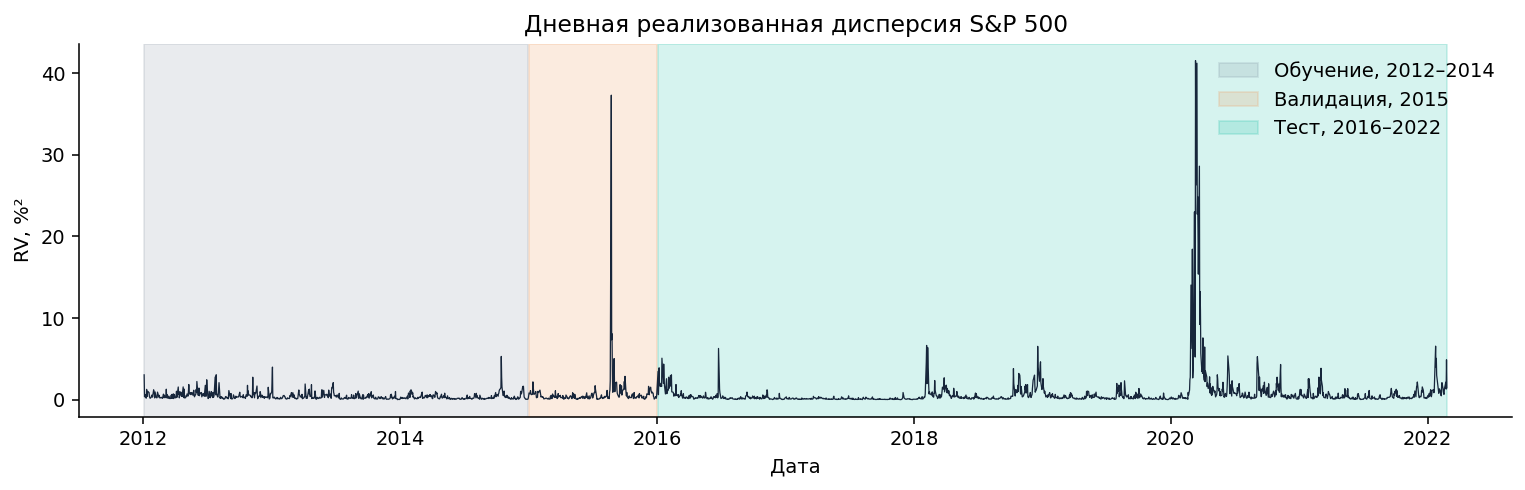

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(y.index, y, color="#17263B", linewidth=0.65)
ax.axvspan(y.index[0], y.index[a - 1], color="#667789", alpha=0.14, label="Обучение, 2012–2014")
ax.axvspan(y.index[a], y.index[b - 1], color="#EF9B60", alpha=0.20, label="Валидация, 2015")
ax.axvspan(y.index[b], y.index[-1], color="#00B89C", alpha=0.16, label="Тест, 2016–2022")
ax.set(title="Дневная реализованная дисперсия S&P 500", ylabel="RV, %²", xlabel="Дата")
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
fig.savefig("results/history.png", dpi=200, bbox_inches="tight")
plt.show()

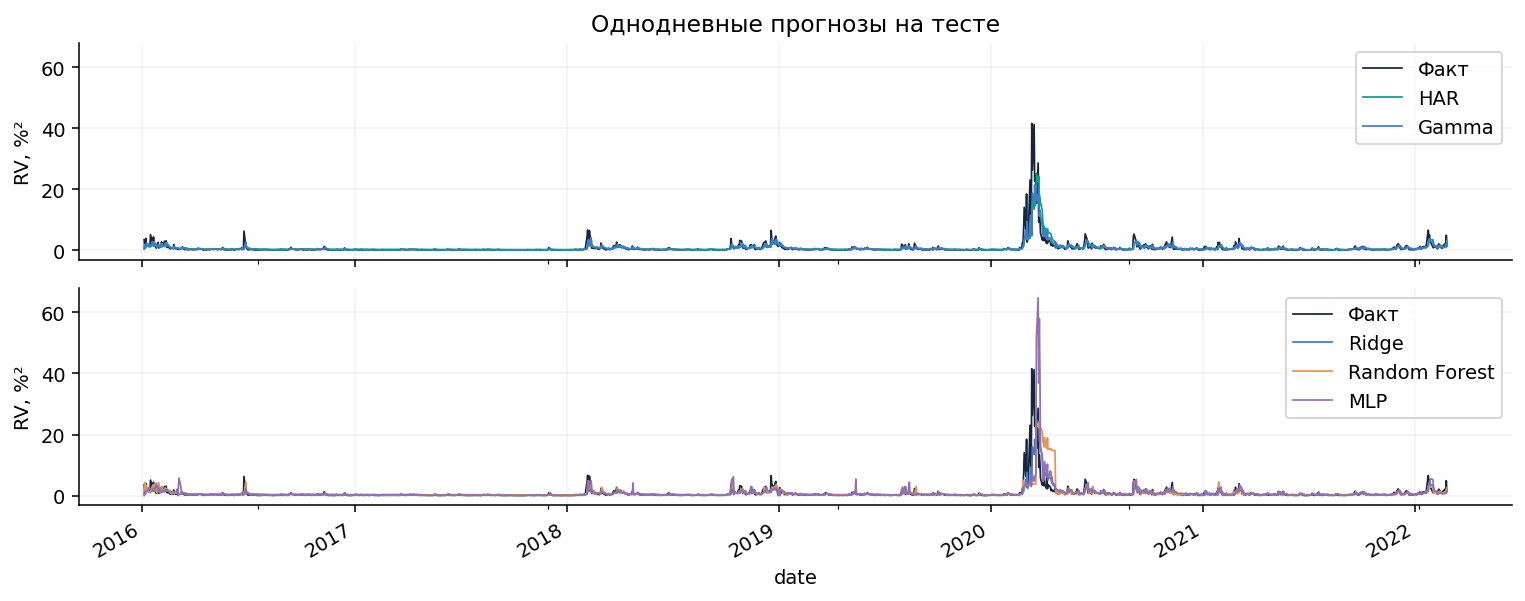

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 4.4), sharex=True, sharey=True)
pred[["Факт", "HAR", "Gamma"]].plot(ax=axes[0], color=["#17263B", "#00A58D", "#407CC9"], linewidth=0.9)
pred[["Факт", "Ridge", "Random Forest", "MLP"]].plot(ax=axes[1], color=["#17263B", "#407CC9", "#E39357", "#9270B2"], linewidth=0.9)
for ax in axes:
    ax.set_ylabel("RV, %²")
    ax.grid(alpha=0.15)
axes[0].set_title("Однодневные прогнозы на тесте")
fig.tight_layout()
fig.savefig("results/forecasts.png", dpi=200, bbox_inches="tight")
plt.show()

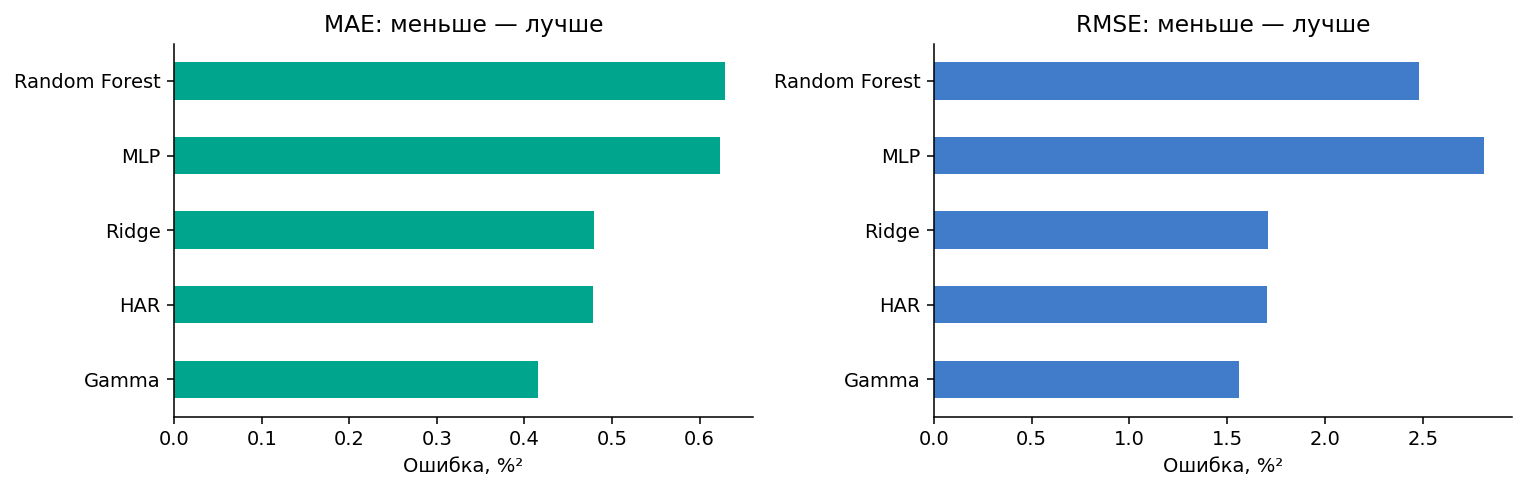

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ordered = scores.sort_values("MAE")
ordered["MAE"].plot.barh(ax=axes[0], color="#00A58D", title="MAE: меньше — лучше")
ordered["RMSE"].plot.barh(ax=axes[1], color="#407CC9", title="RMSE: меньше — лучше")
for ax in axes:
    ax.set_xlabel("Ошибка, %²")
fig.tight_layout()
fig.savefig("results/errors.png", dpi=200, bbox_inches="tight")
plt.show()

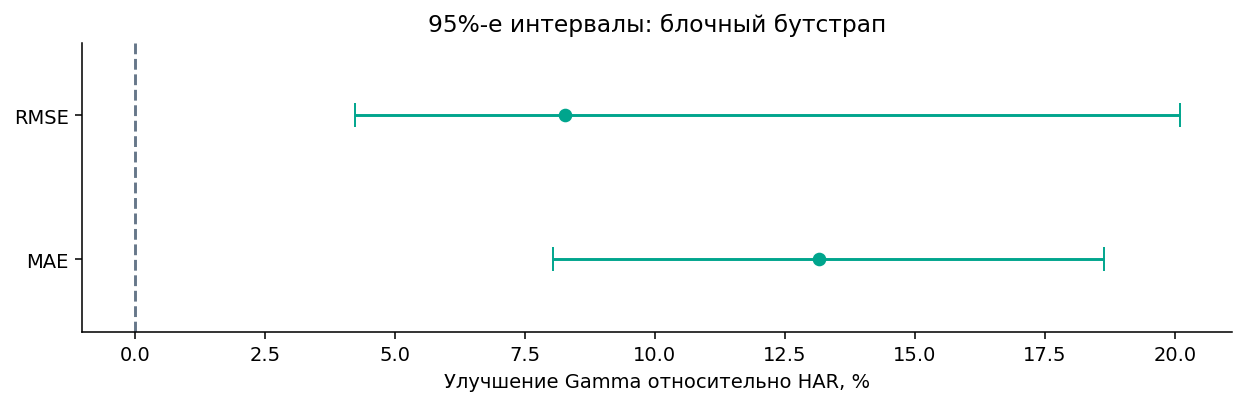

In [10]:
fig, ax = plt.subplots(figsize=(9, 3))
gain = bootstrap["Улучшение, %"].to_numpy()
limits = bootstrap[["Нижняя граница, %", "Верхняя граница, %"]].to_numpy().T
ax.errorbar(gain, [0, 1], xerr=[gain - limits[0], limits[1] - gain], fmt="o", capsize=6, color="#00A58D")
ax.axvline(0, color="#667789", linestyle="--")
ax.set(yticks=[0, 1], yticklabels=["MAE", "RMSE"], xlabel="Улучшение Gamma относительно HAR, %", title="95%-е интервалы: блочный бутстрап")
ax.set_ylim(-0.5, 1.5)
fig.tight_layout()
fig.savefig("results/bootstrap_intervals.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
periods.to_csv("results/periods.csv", index=False)
validation.to_csv("results/validation.csv", index=False)
pred.to_csv("results/predictions.csv", index_label="date")
scores.to_csv("results/metrics.csv", index_label="Модель")
bootstrap.to_csv("results/bootstrap.csv", index_label="Метрика")
np.save("results/bootstrap_samples.npy", np.array(samples))
print(f"Gamma: улучшение MAE к HAR {scores.loc['Gamma', 'Улучшение MAE к HAR, %']:.2f}%.")
print(f"Gamma: улучшение RMSE к HAR {scores.loc['Gamma', 'Улучшение RMSE к HAR, %']:.2f}%.")

Gamma: улучшение MAE к HAR 13.16%.
Gamma: улучшение RMSE к HAR 8.27%.


## Вывод

Gamma снизила MAE относительно HAR на **13,16%** (95%-й интервал: **8,04–18,64%**), RMSE — на **8,27%** (**4,23–20,10%**).

Оба интервала выше нуля. На этом тесте Gamma лучше HAR и остальных моделей по обеим метрикам.

Схему проверки уточняли после первого анализа, поэтому результат пока исследовательский. Его стоит проверить на новом периоде.